## 1. Data Overview and Cleaning

The data below consist of high-entropy alloys (HEAs) with different chemical
compositions. For each alloy, the composition is given in the `Alloy` column, the
number of elements is given in the `Num_el` column, and the phase observed in the
alloy is given in the `Phase` column.

The `Phase` column contains one of five classes:
- **BCC**: body-centered cubic solid solution
- **FCC**: face-centered cubic solid solution
- **BCC+FCC**: a mixture of both BCC and FCC solid solutions
- **IM**: intermetallic compound (ordered crystalline phase with a fixed composition, e.g., Laves or sigma)
- **AM**: amorphous phase (no long-range crystalline order, i.e., metallic glass)

The goal of this first step is to get a general overview of the data: to see what
data we have and how many samples there are in each phase class. We also check the
data for any errors (such as missing values or duplicate entries) and clean them
if any are found.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('Phase_Prediction_merged.csv')

In [3]:
df.head()

,Alloy,Num_el,Phase
0,Al10Cu22.5La22.5Nd22.5Pr22.5,5,AM
1,AlCoCrCu0.5FeNiTi,7,AM
2,AlCoCrFeNiTiVZr,8,AM
3,AlCrMoTaTiZr,6,AM
4,AlCrTaTiZr,5,AM


In [4]:
df.shape

(3190, 3)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3190 entries, 0 to 3189
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Alloy   3190 non-null   str  
 1   Num_el  3190 non-null   int64
 2   Phase   3190 non-null   str  
dtypes: int64(1), str(2)
memory usage: 182.9 KB


In [6]:
df.describe()

,Num_el
count,3190.000000
mean,5.089655
std,0.653610
min,3.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,9.000000


In [7]:
df['Phase'].value_counts()

Phase
BCC        1000
FCC         839
BCC+FCC     671
AM          522
IM          158
Name: count, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

## 2. Data Visualization

In this step, we visualize the data to better understand its structure and to see
patterns that are hard to notice in a table. We plot:

- **Phase distribution:** the number of alloys in each phase class (BCC, FCC,
  BCC+FCC, IM, AM). This shows whether the classes are balanced, which is
  important for training and evaluating the model.
- **Number of elements distribution:** how many alloys contain 3, 4, 5, ... elements,
  to see which composition complexity is most common in the dataset.
- **Number of elements per phase:** how the number of elements in an alloy is
  related to the phase it forms.

These plots give a general picture of the dataset before we move on to building
the model.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

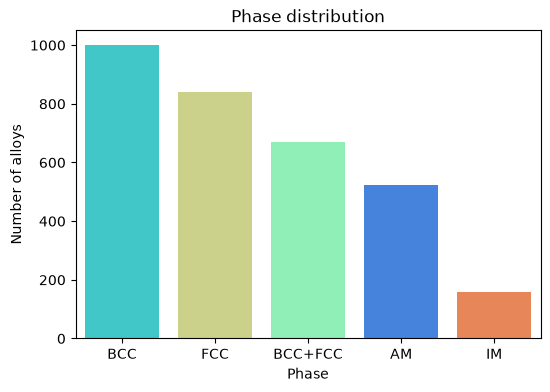

In [10]:
# 1) Phase distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Phase', hue='Phase', palette='rainbow', order=df['Phase'].value_counts().index, legend=False)
plt.title("Phase distribution")
plt.xlabel("Phase")
plt.ylabel("Number of alloys")
plt.show()

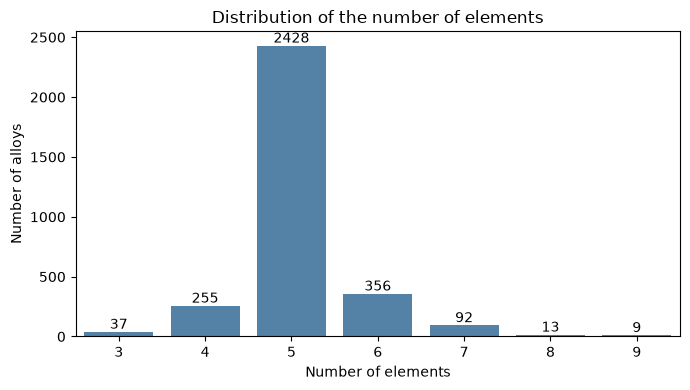

In [11]:
# 2) Number of elements distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="Num_el", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Distribution of the number of elements")
plt.xlabel("Number of elements")
plt.ylabel("Number of alloys")
plt.tight_layout()
plt.show()

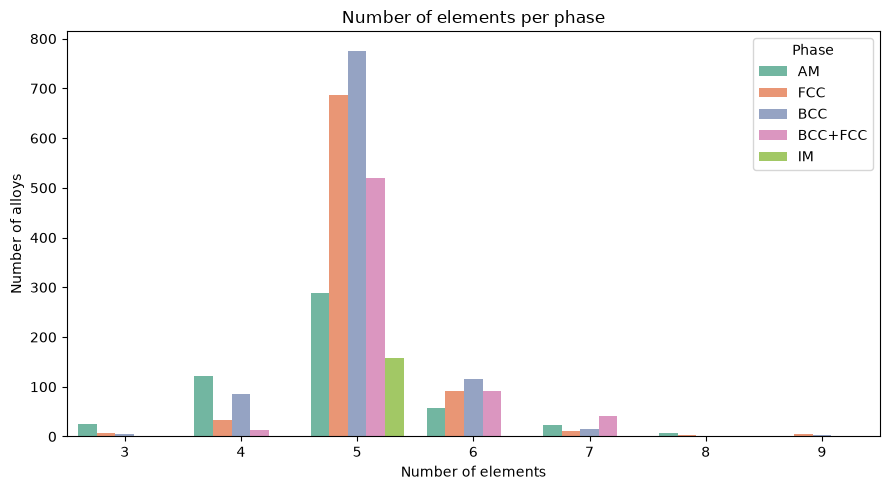

In [12]:
# 3) Number of elements per phase
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x="Num_el", hue="Phase", palette="Set2")
plt.title("Number of elements per phase")
plt.xlabel("Number of elements")
plt.ylabel("Number of alloys")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()

**The plots show that the classes are imbalanced: the BCC class has the most samples, while the IM class has relatively few. This is taken into account in the next steps(e.g., by using a stratified train/test split).**

## 3. Converting Compositions to Element Fractions

The `Alloy` column stores each alloy as a text formula (e.g., `AlCoCrCu0.5FeNiTi`),
and the amounts are written in different scales (relative ratios or atomic percent).
A machine learning model cannot work with text, so in this step we convert every
alloy into a vector of **element fractions** using the `Composition` class from
`pymatgen`.

For each alloy, the amount of every element is divided by the total amount, so that
the fractions of all elements sum to 1. This puts all samples on the same scale and
makes the compositions directly comparable. Each element becomes a separate column
(feature), and elements that are not present in an alloy get a fraction of 0.

The resulting table `x` contains the features, and the `Phase` column is the
target `y`.

In [13]:
!pip install pymatgen

In [14]:
from pymatgen.core import Composition

In [15]:
c = Composition('Al10Cu22.5La22.5Nd22.5Pr22.5')

In [16]:
c

Composition('Al10 Cu22.5 La22.5 Nd22.5 Pr22.5')

In [17]:
c.as_dict()

{'Al': 10.0, 'Cu': 22.5, 'La': 22.5, 'Nd': 22.5, 'Pr': 22.5}

In [18]:
df.head()

,Alloy,Num_el,Phase
0,Al10Cu22.5La22.5Nd22.5Pr22.5,5,AM
1,AlCoCrCu0.5FeNiTi,7,AM
2,AlCoCrFeNiTiVZr,8,AM
3,AlCrMoTaTiZr,6,AM
4,AlCrTaTiZr,5,AM


In [19]:
def to_fraction(Alloy):
    return Composition(Alloy).fractional_composition.as_dict()

In [20]:
to_fraction('AlCoCrCu0.5FeNiTi')

{'Al': 0.15384615384615385,
 'Co': 0.15384615384615385,
 'Cr': 0.15384615384615385,
 'Cu': 0.07692307692307693,
 'Fe': 0.15384615384615385,
 'Ni': 0.15384615384615385,
 'Ti': 0.15384615384615385}

## 4. Feature/Target Split and Train/Test Split

Now that the compositions are converted to element fractions, we separate the data
into inputs and output:

- **Features (`x`):** the element fractions of each alloy
- **Target (`y`):** the `Phase` of each alloy

Next, the data is split into a training set (80%) and a test set (20%). The model
learns from the training set and is evaluated on the test set, which contains
alloys it has never seen. This gives an honest estimate of how well the model
works on new alloys.

As we saw in the visualization step, the classes are imbalanced (some phases have
many more samples than others). A purely random split could leave a rare class
(e.g., IM) under-represented in the test set. To avoid this, we use
`stratify=y`, which keeps the proportion of each phase the same in both the
training and test sets. We also fix `random_state=42` so that the split is
reproducible.

Finally, we train a K-Nearest Neighbors (KNN) classifier on the training data and
eval

In [21]:
x= pd.DataFrame(df['Alloy'].apply(to_fraction).tolist()).fillna(0)

In [22]:
x

,Al,Cu,La,Nd,Pr,Co,Cr,Fe,Ni,Ti,...,Y,Ga,W,Gd,Li,Be,Re,N,Ge,Sc
0,0.100000,0.225000,0.225,0.225,0.225,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.153846,0.076923,0.000,0.000,0.000,0.153846,0.153846,0.153846,0.153846,0.153846,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.125000,0.000000,0.000,0.000,0.000,0.125000,0.125000,0.125000,0.125000,0.125000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.166667,0.000000,0.000,0.000,0.000,0.000000,0.166667,0.000000,0.000000,0.166667,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.200000,0.000000,0.000,0.000,0.000,0.000000,0.200000,0.000000,0.000000,0.200000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3185,0.000000,0.000000,0.000,0.000,0.000,0.000000,0.000000,0.000000,0.000000,0.291715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3186,0.000000,0.000000,0.000,0.000,0.000,0.166667,0.166667,0.166667,0.166667,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3187,0.041667,0.000000,0.000,0.000,0.000,0.166667,0.166667,0.166667,0.166667,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3188,0.083333,0.000000,0.000,0.000,0.000,0.166667,0.166667,0.166667,0.166667,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
y= df['Phase']

In [24]:
y

0            AM
1            AM
2            AM
3            AM
4            AM
         ...   
3185        BCC
3186        FCC
3187    BCC+FCC
3188        BCC
3189        BCC
Name: Phase, Length: 3190, dtype: str

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [27]:
x_train.shape

(2552, 43)

In [28]:
x_test.shape

(638, 43)

In [29]:
from sklearn.neighbors import KNeighborsClassifier

In [30]:
knn = KNeighborsClassifier(n_neighbors= 5)

In [31]:
 knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](5,)","['AM','BCC','BCC+FCC','FCC','IM']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 5. Prediction and Evaluation

After training the KNN model on the training set, we use it to predict the phases
of the test alloys (`x_test`), which the model has never seen. The predicted phases
(`y_pred`) are then compared with the true phases (`y_test)` to measure how well
the model works.

We evaluate the model using:
- **Accuracy:** the percentage of alloys whose phase was predicted correctly.

In [32]:
y_pred = knn.predict(x_test)

In [33]:
y_pred

array(['IM', 'BCC', 'BCC', 'AM', 'IM', 'AM', 'BCC', 'BCC', 'BCC+FCC',
       'FCC', 'BCC', 'AM', 'BCC', 'AM', 'BCC', 'BCC+FCC', 'FCC', 'FCC',
       'FCC', 'BCC+FCC', 'BCC', 'BCC', 'BCC+FCC', 'FCC', 'FCC', 'FCC',
       'AM', 'BCC', 'BCC', 'FCC', 'BCC', 'FCC', 'FCC', 'FCC', 'BCC',
       'BCC', 'BCC', 'FCC', 'FCC', 'BCC', 'BCC', 'AM', 'FCC', 'IM',
       'BCC+FCC', 'FCC', 'FCC', 'BCC', 'BCC+FCC', 'BCC', 'BCC', 'BCC',
       'BCC', 'BCC', 'BCC', 'FCC', 'AM', 'BCC+FCC', 'BCC', 'BCC', 'FCC',
       'BCC+FCC', 'BCC+FCC', 'AM', 'BCC', 'BCC', 'BCC', 'BCC+FCC', 'FCC',
       'FCC', 'BCC+FCC', 'AM', 'BCC+FCC', 'BCC', 'AM', 'FCC', 'BCC',
       'BCC', 'BCC+FCC', 'BCC', 'FCC', 'FCC', 'AM', 'BCC+FCC', 'FCC',
       'FCC', 'BCC+FCC', 'BCC', 'BCC+FCC', 'FCC', 'AM', 'AM', 'BCC',
       'BCC+FCC', 'AM', 'BCC+FCC', 'AM', 'IM', 'FCC', 'FCC', 'AM', 'AM',
       'FCC', 'BCC+FCC', 'BCC', 'BCC', 'AM', 'BCC+FCC', 'BCC+FCC', 'BCC',
       'FCC', 'BCC', 'FCC', 'AM', 'FCC', 'BCC+FCC', 'BCC', 'BCC+FCC',
       

In [34]:
from sklearn.metrics import accuracy_score

In [35]:
accuracy_score(y_test, y_pred)

0.9294670846394985

### Results

The KNN model (k = 5) reached an accuracy of **92.9%** on the test set, meaning
that it predicted the correct phase for about 93 out of every 100 unseen alloys.
This shows that the chemical composition (element fractions) carries enough
information to predict the phase of a high-entropy alloy, and that alloys with
similar compositions tend to form similar phases, which is exactly the assumption
behind the KNN algorithm.

## 6. Validation and Overfitting Check

So far, we chose k = 5 by hand. To choose k properly without touching the test set,
we split the training data again into a smaller training set (`x_tr`, `y_tr`) and a
**validation set** (`x_val`, `y_val`). The test set is kept untouched until the
final evaluation.

For each value of k (from 2 to 30), we train a KNN model and measure the accuracy
on both the training and the validation set. Comparing the two curves is a simple
way to check for **overfitting**:
- If the training accuracy is much higher than the validation accuracy, the model
  has memorized the training data and does not generalize well (overfitting).
- If both accuracies are low, the model is too simple (underfitting).

For KNN, a very small k (e.g., k = 1) usually overfits, because the prediction
depends on a single neighbor, while a very large k makes the model too smooth.

Because a single validation split can be lucky or unlucky, we repeat the split with
four different random seeds and check whether the best k stays similar.

In [36]:
x_train.head()

,Al,Cu,La,Nd,Pr,Co,Cr,Fe,Ni,Ti,...,Y,Ga,W,Gd,Li,Be,Re,N,Ge,Sc
970,0.385397,0.192659,0.0,0.0,0.0,0.00000,0.249948,0.093645,0.078350,0.0,...,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
940,0.326789,0.143430,0.0,0.0,0.0,0.07914,0.353309,0.000000,0.097332,0.0,...,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2032,0.118690,0.139860,0.0,0.0,0.0,0.23282,0.000000,0.218620,0.290010,0.0,...,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1870,0.000000,0.272846,0.0,0.0,0.0,0.00000,0.378345,0.148238,0.155268,0.0,...,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
230,0.000000,0.000000,0.0,0.0,0.0,0.03000,0.000000,0.650000,0.000000,0.0,...,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [37]:
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42, stratify= y_train)

In [38]:
model = KNeighborsClassifier(n_neighbors=5)

In [39]:
model.fit(x_tr, y_tr)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](5,)","['AM','BCC','BCC+FCC','FCC','IM']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [40]:
y_train_pred= model.predict(x_tr)
y_val_pred= model.predict(x_val)

In [41]:
 accuracy_score(y_tr, y_train_pred)

0.9416952474277315

In [42]:
accuracy_score(y_val, y_val_pred)

0.9001956947162426

In [43]:
ks = range(2,31)

In [44]:
train_acc, val_acc= [], []

for k in ks:
    model = KNeighborsClassifier(n_neighbors= k)
    model.fit(x_tr, y_tr)

    y_train_pred = model.predict(x_tr)
    y_val_pred= model.predict(x_val)

    train_acc.append(accuracy_score(y_tr, y_train_pred))
    val_acc.append(accuracy_score(y_val, y_val_pred))
    

In [45]:
train_acc

[0.951984321411073,
 0.9627633512983832,
 0.9446349828515433,
 0.9416952474277315,
 0.9274865262126408,
 0.9191572758451739,
 0.9142577168054875,
 0.9157275845173934,
 0.9054385105340519,
 0.9054385105340519,
 0.9020088192062714,
 0.897109260166585,
 0.8936795688388045,
 0.8892699657030867,
 0.8892699657030867,
 0.8873101420872122,
 0.8833904948554631,
 0.8843704066634003,
 0.8775110240078393,
 0.875061244487996,
 0.8726114649681529,
 0.8716315531602156,
 0.8682018618324351,
 0.8657520823125918,
 0.8642822146006859,
 0.8628123468887801,
 0.8569328760411563,
 0.8564429201371877,
 0.8535031847133758]

Text(0, 0.5, 'Accuracy')

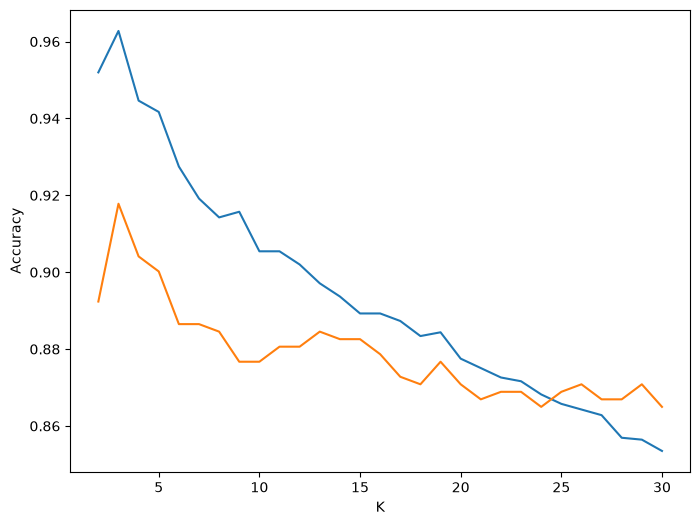

In [46]:
plt.figure(figsize= (8, 6))
plt.plot(ks, train_acc, label= 'Train')
plt.plot(ks, val_acc, label= 'Validation')
plt.xlabel('K')
plt.ylabel('Accuracy')

In [47]:
best_k = ks[np.argmax(val_acc)]

In [48]:
best_k, max(val_acc)

(3, 0.9178082191780822)

### Training vs. Validation Accuracy for Different k

The plot shows the accuracy of the KNN model on the training set (blue) and on the
validation set (orange) for k = 2 to 30.

- **Small k (k = 2–5):** Both accuracies are highest here. The validation accuracy
  reaches its maximum at **k = 3** (91.8%). However, the training accuracy is
  noticeably higher than the validation accuracy (about 96% vs. 92%), which shows a
  small degree of **overfitting**: with very few neighbors, the model follows the
  training data too closely.
- **Increasing k:** As k grows, the gap between training and validation accuracy
  becomes smaller, but both accuracies decrease.
- **Large k (k > 20):** The two curves are almost the same and low (about 85–87%).
  This means the model is too smooth (**underfitting**): with many neighbors, the
  prediction is dominated by the most common phases, so rare classes (e.g., IM) may
  be predicted poorly.

Therefore, a small k (around 3) gives the best balance between overfitting and
underfitting. Since the validation set is small and the curve is noisy, we repeated
the split with 15 different random seeds: k = 3 was the best value in 12 of the 15
splits. We confirm this choice in the next step using 5-fold cross-validation.

In [49]:
for seed in range(1, 16):
    x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=seed)
    acc = [KNeighborsClassifier(k).fit(x_tr, y_tr).score(x_val, y_val) for k in ks]
    print(seed, 'Best k=', ks[np.argmax(acc)], 'accuracy=', max(acc))

1 Best k= 3 accuracy= 0.8923679060665362
2 Best k= 3 accuracy= 0.898238747553816
3 Best k= 3 accuracy= 0.8806262230919765
4 Best k= 3 accuracy= 0.9041095890410958
5 Best k= 3 accuracy= 0.8884540117416829
6 Best k= 4 accuracy= 0.913894324853229
7 Best k= 3 accuracy= 0.8962818003913894
8 Best k= 3 accuracy= 0.9099804305283757
9 Best k= 3 accuracy= 0.9158512720156555
10 Best k= 3 accuracy= 0.913894324853229
11 Best k= 3 accuracy= 0.9295499021526419
12 Best k= 9 accuracy= 0.9041095890410958
13 Best k= 3 accuracy= 0.9119373776908023
14 Best k= 2 accuracy= 0.9217221135029354
15 Best k= 3 accuracy= 0.913894324853229


### Hyperparameter Tuning with GridSearchCV and Choice of k

To make the choice of k more reliable than a single validation split, I used
`GridSearchCV` with 5-fold cross-validation on the training set. In this method,
the training data is divided into 5 parts. Each part is used once for validation
while the other 4 parts are used for training, and the accuracy is averaged over
the 5 folds.

First, I tested k from 1 to 15 with the Euclidean distance (p = 2). Using the
nearest neighbor only (k = 1) gave the highest cross-validation accuracy (91.6%).
However, I did not choose k = 1 for the final model, for two reasons.

First, the advantage is small: k = 3 reaches 90.6%, a difference of about 1%,
which is similar to the fold-to-fold standard deviation (about 1–2%).

Second, k = 1 is likely not reliable for high-entropy alloys. The phase of an
alloy depends on its composition in a non-linear way, and a small change in one
element can change the phase (e.g., adding Al to CoCrFeNi can change FCC to BCC).
With k = 1, the prediction copies the phase of one single alloy, so it is very
sensitive to individual samples and noise. In addition, the dataset contains many
alloys with very similar compositions, so in a random split a validation alloy
often has a near-identical "twin" in the training set. This favors k = 1 and may
make its accuracy optimistic for completely new compositions.

Also, k = 2 can give tied votes between two phases, and its accuracy is lower
(89.2%). Therefore, I searched k from 3 upwards (odd values avoid ties) and also
compared two distance types: p = 1 (Manhattan) and p = 2 (Euclidean). The searched
values were:
- `n_neighbors` (k): 3, 5, 7, 9, 11, 15
- `p`: 1, 2

In [50]:
from sklearn.model_selection import GridSearchCV

In [51]:
param_grid= {
    'n_neighbors':[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    'p':[1,2]
}

In [52]:
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv= 5)

In [53]:
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [1, 2, ...], 'p': [1, 2]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, w

In [54]:
grid.best_params_

{'n_neighbors': 1, 'p': 2}

In [55]:
print(grid.best_score_)

res = pd.DataFrame(grid.cv_results_)
res[res['param_p'] == 2][['param_n_neighbors', 'mean_test_score', 'std_test_score']]

0.9161498023867081


,param_n_neighbors,mean_test_score,std_test_score
1,1,0.916150,0.008290
3,2,0.892251,0.018432
5,3,0.905575,0.016619
7,4,0.897742,0.018841
9,5,0.892646,0.022353
11,6,0.888335,0.026712
13,7,0.888331,0.022004
15,8,0.885196,0.021879
17,9,0.885199,0.022288
19,10,0.878533,0.019569


In [56]:
param_grid= {
    'n_neighbors':[3,5,7,9,11,15],
    'p':[1,2]
}

In [57]:
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv= 5)

In [58]:
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [3, 5, ...], 'p': [1, 2]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, w

In [59]:
grid.best_params_

{'n_neighbors': 3, 'p': 1}

In [60]:
grid.best_score_

np.float64(0.9067510839952421)

**Result of the grid search**

The best combination was **k = 3 and p = 1** (Manhattan distance), with a mean
5-fold cross-validation accuracy of **90.7%**. This is also the value of k that
was most often the best in the repeated train/validation splits (12 of 15). The
next plot shows how the accuracy changes with k for the two distance types.

### Mean Cross-Validation Accuracy vs. k

The plot shows the mean cross-validation accuracy for each value of k, for the two
distance types (p = 1: Manhattan, p = 2: Euclidean).

- **Effect of k:** For both distance types, the accuracy is highest at k = 3
  (about 90.7%) and decreases steadily as k becomes larger, down to about 87% at
  k = 15. With more neighbors, the prediction becomes smoother, so the model can
  no longer follow the local differences between alloys with similar compositions.
- **Effect of distance type:** The two curves are close to each other. The
  Manhattan distance (p = 1) is equal to or slightly better than the Euclidean
  distance (p = 2), with a maximum difference of about 0.6% (at k = 5). This is
  smaller than the fold-to-fold variation, so the choice of distance has only a
  small effect.
- **Choice:** The best result is at k = 3 with p = 1, so this combination was
  used for the final model.

In [61]:
res = pd.DataFrame(grid.cv_results_)

In [62]:
res

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,param_p,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.011321,0.002168,0.036059,0.004244,3,1,"{'n_neighbors': 3, 'p': 1}",0.909980,0.874755,0.925490,0.923529,0.900000,0.906751,0.018506,1
1,0.009452,0.002333,0.010029,0.001096,3,2,"{'n_neighbors': 3, 'p': 2}",0.906067,0.876712,0.913725,0.927451,0.903922,0.905575,0.016619,2
2,0.008603,0.002492,0.033595,0.003652,5,1,"{'n_neighbors': 5, 'p': 1}",0.911937,0.861057,0.917647,0.925490,0.878431,0.898913,0.024817,3
3,0.007795,0.001425,0.010096,0.002264,5,2,"{'n_neighbors': 5, 'p': 2}",0.898239,0.855186,0.907843,0.919608,0.882353,0.892646,0.022353,4
4,0.008631,0.000697,0.039169,0.005291,7,1,"{'n_neighbors': 7, 'p': 1}",0.915851,0.847358,0.905882,0.909804,0.880392,0.891858,0.025322,5
5,0.007664,0.001539,0.010960,0.002587,7,2,"{'n_neighbors': 7, 'p': 2}",0.906067,0.849315,0.896078,0.909804,0.880392,0.888331,0.022004,6
6,0.008301,0.001641,0.033621,0.003723,9,1,"{'n_neighbors': 9, 'p': 1}",0.908023,0.847358,0.898039,0.892157,0.880392,0.885194,0.020925,8
7,0.008194,0.000933,0.012591,0.003008,9,2,"{'n_neighbors': 9, 'p': 2}",0.900196,0.843444,0.905882,0.894118,0.882353,0.885199,0.022288,7
8,0.007850,0.000967,0.034666,0.003862,11,1,"{'n_neighbors': 11, 'p': 1}",0.892368,0.843444,0.882353,0.888235,0.882353,0.877751,0.017566,9
9,0.008507,0.001482,0.010185,0.001576,11,2,"{'n_neighbors': 11, 'p': 2}",0.896282,0.841487,0.888235,0.880392,0.882353,0.877750,0.018955,10


In [63]:
res= res[res['param_p']==1]

In [64]:
res

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,param_p,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.011321,0.002168,0.036059,0.004244,3,1,"{'n_neighbors': 3, 'p': 1}",0.909980,0.874755,0.925490,0.923529,0.900000,0.906751,0.018506,1
2,0.008603,0.002492,0.033595,0.003652,5,1,"{'n_neighbors': 5, 'p': 1}",0.911937,0.861057,0.917647,0.925490,0.878431,0.898913,0.024817,3
4,0.008631,0.000697,0.039169,0.005291,7,1,"{'n_neighbors': 7, 'p': 1}",0.915851,0.847358,0.905882,0.909804,0.880392,0.891858,0.025322,5
6,0.008301,0.001641,0.033621,0.003723,9,1,"{'n_neighbors': 9, 'p': 1}",0.908023,0.847358,0.898039,0.892157,0.880392,0.885194,0.020925,8
8,0.007850,0.000967,0.034666,0.003862,11,1,"{'n_neighbors': 11, 'p': 1}",0.892368,0.843444,0.882353,0.888235,0.882353,0.877751,0.017566,9
10,0.008273,0.000902,0.036302,0.003542,15,1,"{'n_neighbors': 15, 'p': 1}",0.896282,0.833659,0.872549,0.868627,0.874510,0.869126,0.020180,11


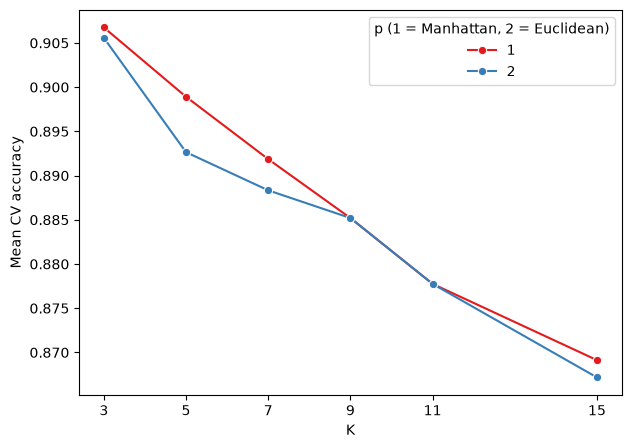

In [65]:
res = pd.DataFrame(grid.cv_results_)          # fresh, unfiltered
res['param_p'] = res['param_p'].astype(int)
res['param_n_neighbors'] = res['param_n_neighbors'].astype(int)

plt.figure(figsize=(7, 5))
sns.lineplot(data=res, x='param_n_neighbors', y='mean_test_score',
             hue='param_p', marker='o', palette='Set1')
plt.xticks([3, 5, 7, 9, 11, 15])
plt.xlabel('K')
plt.ylabel('Mean CV accuracy')
plt.legend(title='p (1 = Manhattan, 2 = Euclidean)')
plt.show()

As can be seen in the plot, the accuracy is highest at k = 3 for both distance
types (about 90.7% for Manhattan and 90.6% for Euclidean) and decreases steadily
as k becomes larger, reaching about 87% at k = 15. The two curves are very close
to each other, and the Manhattan distance (p = 1) is equal to or slightly better
than the Euclidean distance (p = 2) for all values of k. This small difference
shows that the choice of distance has only a minor effect, and therefore k = 3
with p = 1 was used for the final model.

### Effect of Feature Scaling

KNN is based on distances, so the scale of the features can affect the result.
Since all features are element fractions between 0 and 1, scaling may not be
necessary. To check this, I compared three options using 5-fold cross-validation
on the training set, with the best parameters found above (k = 3, p = 1):
- raw element fractions
- `MinMaxScaler`
- `StandardScaler`

In [66]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [67]:
best_k = grid.best_params_['n_neighbors']
best_p = grid.best_params_['p']
print(best_k, best_p)

3 1


In [68]:
models= {
    'Raw fraction': KNeighborsClassifier(n_neighbors=best_k, p=best_p),
    'MinMax': make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=best_k, p=best_p)),
    'StandardScaler': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, p=best_p))
}

In [69]:
from sklearn.model_selection import cross_val_score

In [70]:
scores= {name: cross_val_score(m, x_train, y_train, cv=5).mean() for name, m in models.items()}

In [71]:
models.items()

dict_items([('Raw fraction', KNeighborsClassifier(n_neighbors=3, p=1)), ('MinMax', Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(n_neighbors=3, p=1))])), ('StandardScaler', Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(n_neighbors=3, p=1))]))])

In [72]:
scores

{'Raw fraction': np.float64(0.9067510839952421),
 'MinMax': np.float64(0.9020475039330801),
 'StandardScaler': np.float64(0.9028310502283106)}

The mean accuracies were 90.7% (raw fractions), 90.2% (`MinMaxScaler`), and 90.3%
(`StandardScaler`). Scaling did not improve the accuracy, and the differences are
smaller than the fold-to-fold variation. Therefore, I used the raw element
fractions. A possible reason is that scaling changes how much each element
contributes to the distance: for example, `StandardScaler` gives a rare element
the same weight as a common one, which may not be physically meaningful for
alloys.

## Final Evaluation on the Test Set

The best model from the grid search (k = 3, p = 1, raw element fractions) is
evaluated once on the test set, which was not used for choosing any parameter.

In [73]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

Test accuracy: 0.9388714733542319
              precision    recall  f1-score   support

          AM       0.97      0.99      0.98       104
         BCC       0.93      0.95      0.94       200
     BCC+FCC       0.88      0.86      0.87       134
         FCC       0.96      0.96      0.96       168
          IM       1.00      0.94      0.97        32

    accuracy                           0.94       638
   macro avg       0.95      0.94      0.94       638
weighted avg       0.94      0.94      0.94       638



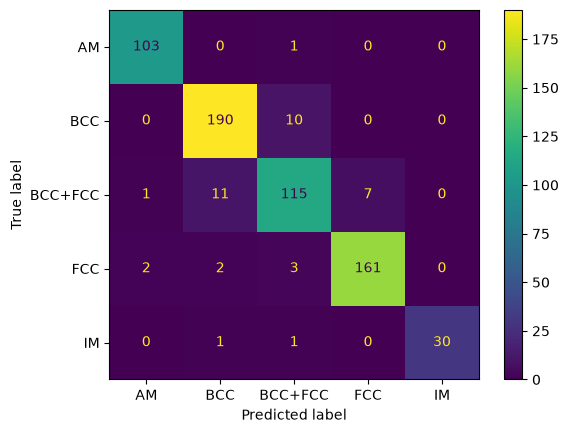

In [74]:
best_knn = grid.best_estimator_
y_pred = best_knn.predict(x_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

### Results

The final model (KNN with k = 3 and p = 1) reached a test accuracy of **93.9%**:
599 of the 638 test alloys were predicted correctly. The test accuracy is similar to
(and slightly higher than) the cross-validation accuracy (90.7%), so the model does
not show signs of overfitting. The small difference may come from the fact that the
final model is trained on the whole training set and that the test set is a single
sample of 638 alloys.

| Phase | Precision | Recall | F1-score | Test samples |
|---|---|---|---|---|
| AM | 0.97 | 0.99 | 0.98 | 104 |
| BCC | 0.93 | 0.95 | 0.94 | 200 |
| BCC+FCC | 0.88 | 0.86 | 0.87 | 134 |
| FCC | 0.96 | 0.96 | 0.96 | 168 |
| IM | 1.00 | 0.94 | 0.97 | 32 |

As can be seen in the classification report and the confusion matrix, AM, FCC and
IM are predicted very well. The lowest scores belong to the BCC+FCC class (F1 =
0.87). Most of the errors (34 of 39) involve this class, and the most common
mistake is confusion between BCC and BCC+FCC (21 alloys). This is reasonable
because BCC+FCC is a mixture of the two other solid solutions, so alloys with
compositions near the border between BCC and FCC are the hardest to classify.

Note that the IM class has only 32 test samples, so its scores are less certain than
those of the larger classes. Also, since similar compositions can appear in both the
training and test sets, the accuracy may be optimistic for completely new alloys.

## Conclusion

In this project, I built a K-Nearest Neighbors model to predict the phase of
high-entropy alloys (BCC, FCC, BCC+FCC, IM, AM) from their chemical composition.
The alloy formulas of 3190 alloys were converted to the fractions of 43 elements,
which were used as the input features.

The model parameters were chosen only on the training set, using a validation
split and 5-fold cross-validation. k = 1 gave the highest cross-validation
accuracy, but I did not use it because the advantage was small and it is likely
not reliable for new compositions. The final model (k = 3, Manhattan distance)
reached an accuracy of **93.9%** on the test set. Scaling the features did not
improve the result.

AM, FCC and IM alloys were predicted very well. The BCC+FCC class was the most
difficult (F1 = 0.87), and most errors were confusions between BCC and BCC+FCC,
which is reasonable because BCC+FCC is a mixture of the two structures.

**Limitations:** only the composition was used, similar alloys may appear in both
the training and test sets (so the accuracy may be optimistic for completely new
alloys), and the IM class has only 32 test samples.

**Future work:** adding physical descriptors (mixing entropy and enthalpy, atomic
size mismatch, valence electron concentration), comparing other models (e.g.,
Random Forest, XGBoost), using grouped cross-validation to avoid near-duplicate
alloys in the validation folds, and applying the model to laser-cladded HEAs.